# Country ground truth

This notebook builds the country table for the image-representation study from the two World Bank files in `data/raw`.

- `CLASS_2026_07_15.csv` gives the current income group, region, and ISO code.
- `API_SP.URB.TOTL.IN.ZS_DS2_en_excel_v2_2441.csv` gives urban population as a percent of total population for 1960–2025.

The table keeps 196 countries: the 193 UN member states plus Kosovo, Taiwan, and Palestine. Aggregate rows such as "World" and "High income" are dropped. Territories, dependencies, and constituent economies in the World Bank list, such as Bermuda, the Cayman Islands, and Hong Kong SAR, are not counted. Vatican City is absent from the source.

The Google Images query uses the State Department short-form name from `data/raw/IndependentStates_Dependencies_INRGGI_08102026.csv`. The original World Bank label is kept as `world_bank_name`.

Taiwan stays in the table with income only. The urbanization file has no Taiwan row, so charts that need a percent omit it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
INCOME_PATH = RAW / "CLASS_2026_07_15.csv"
URBAN_PATH = RAW / "API_SP.URB.TOTL.IN.ZS_DS2_en_excel_v2_2441.csv"
OUTPUT_PATH = ROOT / "data" / "processed" / "countries.csv"
URBAN_YEAR = "2025"

INCOME_ORDER = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income",
]
BINARY_MAP = {
    "Low income": "Low or lower-middle",
    "Lower middle income": "Low or lower-middle",
    "Upper middle income": "High or upper-middle",
    "High income": "High or upper-middle",
}
EXCLUDED_ISO_CODES = {
    "ASM",  # American Samoa
    "GUM",  # Guam
    "MNP",  # Northern Mariana Islands
    "PRI",  # Puerto Rico
    "VIR",  # U.S. Virgin Islands
    "BMU",  # Bermuda
    "VGB",  # British Virgin Islands
    "CYM",  # Cayman Islands
    "GIB",  # Gibraltar
    "TCA",  # Turks and Caicos Islands
    "ABW",  # Aruba
    "CUW",  # Curaçao
    "SXM",  # Sint Maarten (Dutch part)
    "FRO",  # Faroe Islands
    "GRL",  # Greenland
    "PYF",  # French Polynesia
    "NCL",  # New Caledonia
    "MAF",  # St. Martin (French part)
    "CHI",  # Channel Islands
    "IMN",  # Isle of Man
    "HKG",  # Hong Kong SAR
    "MAC",  # Macao SAR
}
SHORT_FORM_PATH = RAW / "IndependentStates_Dependencies_INRGGI_08102026.csv"
SEARCH_NAME_OVERRIDES = {
    "Korea, South": "South Korea",
    "Korea, North": "North Korea",
    "Gambia, The": "The Gambia",
    "Bahamas, The": "The Bahamas",
    "Micronesia, Federated States of": "Federated States of Micronesia",
}


def to_search_name(short_form, iso_code):
    name = str(short_form).replace("\u00a0", " ").replace("\u2019", "'")
    name = " ".join(name.split())
    if iso_code == "COG":
        return "Republic of the Congo"
    return SEARCH_NAME_OVERRIDES.get(name, name)

for path in (INCOME_PATH, URBAN_PATH, SHORT_FORM_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Expected {path.name} in {path.parent}")

## Load and join

The income file is Windows-1252. Rows with a blank income group are World Bank aggregates or empty lines, so they are removed before the join. Territories, dependencies, and constituent economies are removed next. The State Department short-form file is Windows-1252 as well. Urbanization is the 2025 value. Countries present only in the income file are kept, with a blank percent.

In [2]:
income_raw = pd.read_csv(INCOME_PATH, encoding="cp1252")
urban_raw = pd.read_csv(URBAN_PATH, encoding="utf-8-sig")

income = income_raw.rename(
    columns={
        "Economy": "country_name",
        "Code": "iso_code",
        "Region": "region",
        "Income group": "development_status",
    }
)[["country_name", "iso_code", "region", "development_status"]].copy()

for column in income.columns:
    income[column] = income[column].fillna("").astype(str).str.strip()

income = income.loc[
    income["iso_code"].ne("") & income["development_status"].ne("")
].copy()
dropped = income.loc[income["iso_code"].isin(EXCLUDED_ISO_CODES)].copy()
income = income.loc[~income["iso_code"].isin(EXCLUDED_ISO_CODES)].copy()
income.loc[income["iso_code"].eq("NRU"), "country_name"] = "Nauru"

urban = urban_raw.rename(
    columns={
        "Country Code": "iso_code",
        URBAN_YEAR: "actual_urban_population_pct",
    }
)[["iso_code", "actual_urban_population_pct"]].copy()
urban["iso_code"] = urban["iso_code"].astype(str).str.strip()
urban["actual_urban_population_pct"] = pd.to_numeric(
    urban["actual_urban_population_pct"], errors="coerce"
)

countries = income.merge(urban, on="iso_code", how="left")
countries["income_status_binary"] = countries["development_status"].map(BINARY_MAP)
countries["urban_year"] = pd.Series(pd.NA, index=countries.index, dtype="Int64")
has_urban = countries["actual_urban_population_pct"].notna()
countries.loc[has_urban, "urban_year"] = int(URBAN_YEAR)
short_forms = pd.read_csv(SHORT_FORM_PATH, encoding="cp1252")
short_forms["iso_code"] = short_forms["GENC_3A_CODE"].astype(str).str.strip()
short_forms.loc[short_forms["iso_code"].eq("XKS"), "iso_code"] = "XKX"
short_status = short_forms["STATUS"].fillna("").str.strip()
short_forms = short_forms.loc[
    short_status.eq("Independent") | short_forms["iso_code"].eq("TWN"),
    ["iso_code", "SHORT_FORM_NAME"],
]
countries = countries.merge(short_forms, on="iso_code", how="left")
countries.loc[countries["iso_code"].eq("PSE"), "SHORT_FORM_NAME"] = "Palestine"
countries["world_bank_name"] = countries["country_name"]
countries["country_name"] = [
    to_search_name(short_form, iso_code)
    for short_form, iso_code in zip(
        countries["SHORT_FORM_NAME"], countries["iso_code"], strict=True
    )
]
countries = countries.drop(columns=["SHORT_FORM_NAME"])

countries["development_status"] = pd.Categorical(
    countries["development_status"], categories=INCOME_ORDER, ordered=True
)
countries = countries.sort_values(
    ["development_status", "country_name"]
).reset_index(drop=True)
countries = countries[
    [
        "country_name",
        "world_bank_name",
        "iso_code",
        "region",
        "development_status",
        "income_status_binary",
        "actual_urban_population_pct",
        "urban_year",
    ]
]

missing_urban = countries.loc[
    countries["actual_urban_population_pct"].isna(), "iso_code"
].tolist()
percent = countries["actual_urban_population_pct"].dropna()

assert countries["iso_code"].is_unique
assert len(countries) == 196
assert set(dropped["iso_code"]) == EXCLUDED_ISO_CODES
assert set(countries["development_status"].astype(str)) == set(INCOME_ORDER)
assert countries["income_status_binary"].notna().all()
assert missing_urban == ["TWN"]
assert percent.between(0, 100).all()
assert countries["country_name"].notna().all()
assert countries["country_name"].astype(str).str.strip().ne("").all()
assert not countries["country_name"].isin(["nan", "None"]).any()
expected_names = {
    "KOR": "South Korea",
    "PRK": "North Korea",
    "GMB": "The Gambia",
    "BHS": "The Bahamas",
    "FSM": "Federated States of Micronesia",
    "COG": "Republic of the Congo",
    "COD": "Democratic Republic of the Congo",
    "PSE": "Palestine",
    "XKX": "Kosovo",
    "TWN": "Taiwan",
    "CIV": "C\u00f4te d'Ivoire",
}
for iso_code, expected in expected_names.items():
    actual = countries.loc[countries["iso_code"].eq(iso_code), "country_name"].iloc[0]
    assert actual == expected, (iso_code, actual)

print(f"{len(countries)} countries in the study")
print(f"{int(has_urban.sum())} have a {URBAN_YEAR} urbanization percent")
print(f"Excluded {len(dropped)} territories, dependencies, and constituent economies")
display(dropped.sort_values("country_name")[["country_name", "iso_code"]])
countries.loc[countries["iso_code"].eq("TWN")]

196 countries in the study
195 have a 2025 urbanization percent
Excluded 22 territories, dependencies, and constituent economies


,country_name,iso_code
3,American Samoa,ASM
9,Aruba,ABW
21,Bermuda,BMU
27,British Virgin Islands,VGB
36,Cayman Islands,CYM
39,Channel Islands,CHI
50,Curaçao,CUW
65,Faroe Islands,FRO
69,French Polynesia,PYF
75,Gibraltar,GIB


,country_name,world_bank_name,iso_code,region,development_status,income_status_binary,actual_urban_population_pct,urban_year
189,Taiwan,"Taiwan, China",TWN,East Asia & Pacific,High income,High or upper-middle,NaN,<NA>


## Class balance and missingness

`income_status_binary` collapses the four World Bank groups: low and lower-middle on one side, upper-middle and high on the other. Taiwan is counted in the income totals and excluded from the urbanization totals.

In [3]:
income_counts = (
    countries["development_status"]
    .value_counts()
    .reindex(INCOME_ORDER)
    .rename("countries")
    .to_frame()
)
income_counts["with_urbanization"] = (
    countries.dropna(subset=["actual_urban_population_pct"])["development_status"]
    .value_counts()
    .reindex(INCOME_ORDER)
    .astype("Int64")
)
binary_counts = (
    countries["income_status_binary"]
    .value_counts()
    .reindex(["Low or lower-middle", "High or upper-middle"])
    .rename("countries")
    .to_frame()
)
region_counts = (
    countries.groupby("region", observed=True)
    .size()
    .rename("countries")
    .sort_values(ascending=False)
    .to_frame()
)

print("Four-tier income group")
display(income_counts)
print("Binary collapse")
display(binary_counts)
print("Region")
display(region_counts)

Four-tier income group


,countries,with_urbanization
development_status,,
Low income,25,25
Lower middle income,47,47
Upper middle income,59,59
High income,65,64


Binary collapse


,countries
income_status_binary,
Low or lower-middle,72
High or upper-middle,124


Region


,countries
region,
Europe & Central Asia,53
Sub-Saharan Africa,48
Latin America & Caribbean,33
East Asia & Pacific,31
"Middle East, North Africa, Afghanistan & Pakistan",23
South Asia,6
North America,2


## Urbanization against income and region

These charts describe actual urbanization. They are the baseline the image study will later compare with search results. Very high or very low percents, including city-states, stay in the table.

Urban population, 2025, percent of total


,countries,median,mean,minimum,maximum
development_status,,,,,
Low income,25,34.5,38.3,17.6,72.1
Lower middle income,47,50.9,50.4,15.8,91.0
Upper middle income,59,65.4,62.7,17.5,93.2
High income,64,80.0,76.0,14.6,100.0


,countries,median,mean,minimum,maximum
region,,,,,
South Asia,6,39.1,40.4,20.5,67.0
Sub-Saharan Africa,48,44.9,46.2,17.6,92.1
East Asia & Pacific,30,63.1,57.8,15.8,100.0
Latin America & Caribbean,33,66.2,64.8,24.3,95.7
Europe & Central Asia,53,69.6,69.0,14.6,100.0
"Middle East, North Africa, Afghanistan & Pakistan",23,79.5,75.8,25.9,100.0
North America,2,81.5,81.5,80.2,82.9


,end,country_name,iso_code,development_status,actual_urban_population_pct
0,lowest,Liechtenstein,LIE,High income,14.6
1,lowest,Papua New Guinea,PNG,Lower middle income,15.8
2,lowest,Samoa,WSM,Upper middle income,17.5
3,lowest,Malawi,MWI,Low income,17.6
4,lowest,Niger,NER,Low income,18.4
5,lowest,Sri Lanka,LKA,Upper middle income,20.5
6,lowest,Tonga,TON,Upper middle income,21.2
7,lowest,South Sudan,SSD,Low income,21.7
8,highest,Bahrain,BHR,High income,100.0
9,highest,Kuwait,KWT,High income,100.0


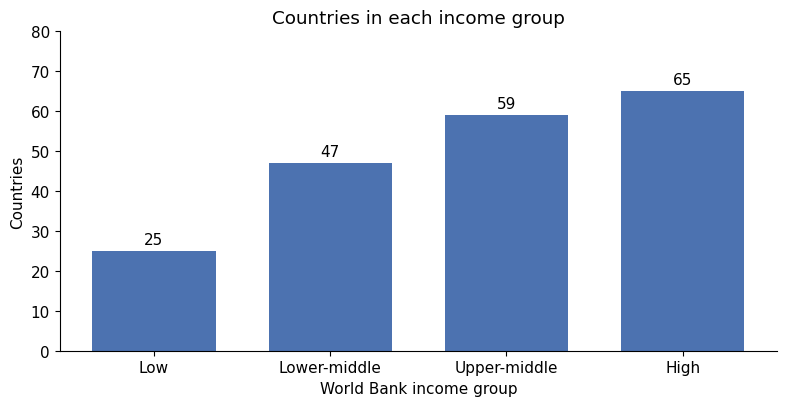

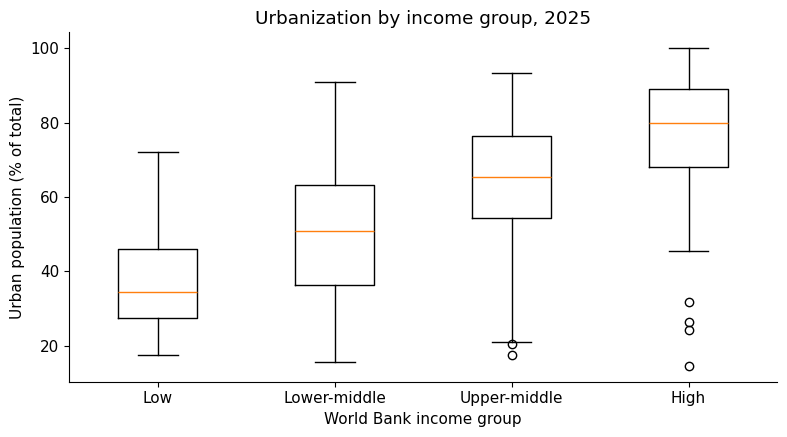

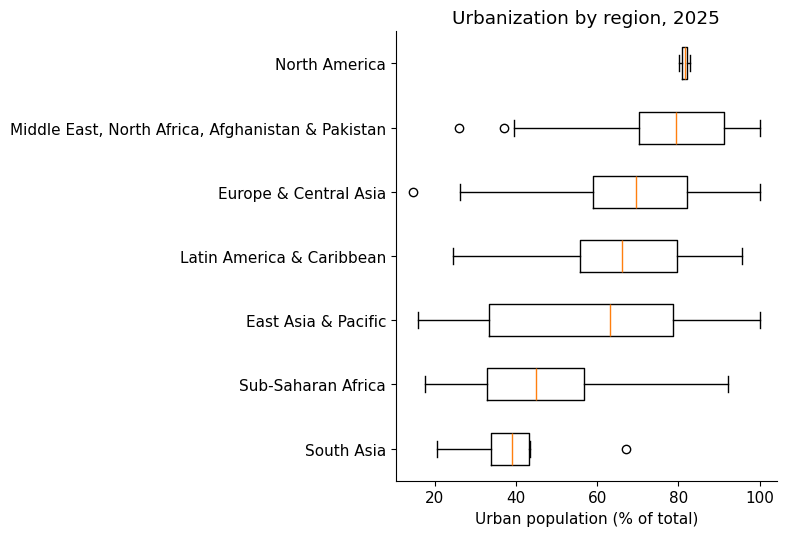

In [4]:
with_urban = countries.dropna(subset=["actual_urban_population_pct"]).copy()

by_income = (
    with_urban.groupby("development_status", observed=True)[
        "actual_urban_population_pct"
    ]
    .agg(countries="count", median="median", mean="mean", minimum="min", maximum="max")
    .round(1)
)
by_region = (
    with_urban.groupby("region", observed=True)["actual_urban_population_pct"]
    .agg(countries="count", median="median", mean="mean", minimum="min", maximum="max")
    .sort_values("median")
    .round(1)
)
extremes = pd.concat(
    [
        with_urban.nsmallest(8, "actual_urban_population_pct").assign(end="lowest"),
        with_urban.nlargest(8, "actual_urban_population_pct").assign(end="highest"),
    ],
    ignore_index=True,
)

print(f"Urban population, {URBAN_YEAR}, percent of total")
display(by_income)
display(by_region)
display(
    extremes[
        [
            "end",
            "country_name",
            "iso_code",
            "development_status",
            "actual_urban_population_pct",
        ]
    ].round({"actual_urban_population_pct": 1})
)

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(
    ["Low", "Lower-middle", "Upper-middle", "High"],
    income_counts["countries"].to_numpy(),
    color="#4C72B0",
    width=0.7,
)
ax.set_ylabel("Countries")
ax.set_xlabel("World Bank income group")
ax.set_title("Countries in each income group")
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, income_counts["countries"].max() + 15)
fig.tight_layout()
plt.show()

income_series = [
    with_urban.loc[
        with_urban["development_status"].eq(group), "actual_urban_population_pct"
    ]
    for group in INCOME_ORDER
]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(income_series, showfliers=True)
ax.set_xticks(
    range(1, len(INCOME_ORDER) + 1),
    ["Low", "Lower-middle", "Upper-middle", "High"],
)
ax.set_ylabel("Urban population (% of total)")
ax.set_xlabel("World Bank income group")
ax.set_title(f"Urbanization by income group, {URBAN_YEAR}")
fig.tight_layout()
plt.show()

region_order = by_region.index.tolist()
region_series = [
    with_urban.loc[with_urban["region"].eq(region), "actual_urban_population_pct"]
    for region in region_order
]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.boxplot(region_series, vert=False, showfliers=True)
ax.set_yticks(range(1, len(region_order) + 1), region_order)
ax.set_xlabel("Urban population (% of total)")
ax.set_title(f"Urbanization by region, {URBAN_YEAR}")
fig.tight_layout()
plt.show()

## Save the country table

The saved file is the ground truth later image rows will join to. `actual_urban_population_pct` stays out of any model that predicts income. It is the benchmark those image results will be compared with.

In [5]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
countries.to_csv(OUTPUT_PATH, index=False)
print(f"Wrote {len(countries)} rows to {OUTPUT_PATH}")

Wrote 196 rows to C:\Users\Admin\Desktop\GIRD\data\processed\countries.csv


## Waiting on image records

The rest of the study needs one row per retained search image: country, image URL, search rank, and the three dominant Cloud Vision labels. Those rows are what produce scene category, the preprocessing comparison, the decision tree, random forest, and logistic regression models, the four-tier versus binary comparison, feature importance, and the mismatch ranking.

A separate Taiwan urbanization figure is still optional. Add it only if Taiwan should be included in that mismatch ranking.

## Image pilot

`collect.py` searches Malawi, Kenya, Brazil, and Japan, then writes `data/processed/images_pilot.csv`. This cell only reads that file.

In [6]:
pilot_path = ROOT / "data" / "processed" / "images_pilot.csv"
excluded_path = ROOT / "data" / "processed" / "excluded_pilot.csv"
if not pilot_path.exists():
    print("No image pilot file yet. Run python collect.py")
else:
    pilot = pd.read_csv(pilot_path)
    kept_counts = pilot.groupby("country_name").size().rename("kept").to_frame()
    print("Kept photos")
    display(kept_counts)
    display(
        pilot[
            [
                "country_name",
                "search_rank",
                "dominant_label_1",
                "dominant_label_2",
                "dominant_label_3",
            ]
        ].head(12)
    )
    if excluded_path.exists():
        excluded = pd.read_csv(excluded_path)
        print("Exclusion reasons")
        display(excluded["reason"].value_counts().rename("rows").to_frame())


Kept photos


,kept
country_name,
Brazil,10
Japan,10
Kenya,10
Malawi,10


,country_name,search_rank,dominant_label_1,dominant_label_2,dominant_label_3
0,Malawi,1,Landscape,Village,Boat
1,Malawi,2,Blue,Water,Body of water
2,Malawi,3,Body of water,Coastal and oceanic landforms,Tourist attraction
3,Malawi,4,Water,Recreation,Lake
4,Malawi,5,Elephant,Watercraft,Wetland
5,Malawi,6,Blue,Water resources,Natural landscape
6,Malawi,7,Mountain,Mountainous landforms,Hill
7,Malawi,8,Daytime,Building,City
8,Malawi,9,Mountain,Mountainous landforms,Green
9,Malawi,10,Water,Body of water,Sea


Exclusion reasons


,rows
reason,
encyclopedia,5
map,5
flag,2
